# Cashi RAG: executed demo and verification

## Problem
Business users ask spending questions in natural language ("payroll in direccion norte, week 38"). The system must understand the question, compute the answer from the data and show how it got it, not just generate fluent text.

## Data
Synthetic demo data created by `seed_demo_data.py` (774 rows: cost centers, account groups, weeks, series R25 = real 2025, R26 = real 2026, P26 = plan 2026). No corporate data is used.

## Method
The engine (`rag/financial_rag.py`) combines: natural-language understanding of the filters (entity and period resolution, lexicon, intent classifier), a numeric engine that queries the aggregates (DuckDB/parquet) so figures are computed rather than generated, and a BM25 retriever over documentation for knowledge questions. Every answer returns its SQL lineage. This notebook (1) runs real questions, (2) checks the engine's numbers against an independent pandas computation, and (3) measures latency.

In [1]:
import sys, os, time, warnings; warnings.filterwarnings('ignore')
os.chdir(os.path.dirname(os.path.abspath('__file__'))) if os.path.basename(os.getcwd())=='notebooks' else None
sys.path.insert(0, os.getcwd())
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import rag.financial_rag as F, rag.query as Q
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
engine = F.UnifiedCashiRAGEngine()
print('engine ready; demo meta:', pd.read_json('aggs/_meta.json', typ='series').to_dict())

engine ready; demo meta: {'sem_max_real': 43, 'sem_max_plan': 53, 'source': 'synthetic-demo', 'generated_by': 'seed_demo_data.py'}


In [2]:
def ask(q):
    t = time.perf_counter(); r = engine.process_query(q); return r, (time.perf_counter()-t)*1000
qs = ['gasto de nomina en direccion norte semana 38', 'top 5 territorios por gasto', 'variacion contra presupuesto por division', 'cuanto gastamos en fletes y transportes', 'que cuentas tienen mayor gasto semana 20']
for q in qs:
    r, ms = ask(q)
    print('Q:', q, f'({ms:.0f} ms)'); print('  tipo:', r.get('tipo_respuesta'), '| intencion:', r.get('intencion_detectada')); print('  ', r.get('titulo')); print('  ', str(r.get('respuesta_ejecutiva'))[:300].replace('\n',' ')); print()

Q: gasto de nomina en direccion norte semana 38 (95 ms)
  tipo: financiera | intencion: Consulta Financiera Estructurada
   Resumen Financiero: División 'Direccion Norte' + Grupo 'Gastos de Nomina' (Sem 38–38)
   ### 💼 Resumen Ejecutivo (División 'Direccion Norte' + Grupo 'Gastos de Nomina') - **Real 2026:** 0.68 MDP - **Plan 2026:** 0.67 MDP - **Real 2025:** 0.61 MDP - **Variación vs Plan:** **0.02 MDP** (+3.0%) — **Desfavorable (Sobreconsumo) 🔴**  *(Nota: Cifras consolidadas en millones de pesos de la sema

Q: top 5 territorios por gasto (29 ms)
  tipo: financiera | intencion: Ranking Top 5 CECOs con Mayor Variación vs Plan
   Top 5 Variaciones por CECO (Consolidado Global, Semanas 1–43)
   ### 📊 Resumen Ejecutivo En el periodo acumulado de la **semana 1 a la 43** (Consolidado Global), los 5 CECOs con mayor variación suman una desviación combinada de **2.57 MDP** respecto al Plan 2026.  **Principales hallazgos:** - La mayor variación se concentra en **CECO MTO-004** (Todos los grupos

In [3]:
# Table + SQL lineage for one answer
r, _ = ask('gasto de nomina en direccion norte semana 38')
print(pd.DataFrame(r['tabla']).round(0).to_string(index=False))
print('\nFilters resolved:', r.get('filtros_resueltos'))
print('\nSQL executed:\n', (r.get('sql_linaje') or {}).get('sql_ejecutado', '(no sql)'))

             Concepto  Real_2026  Plan_2026  Real_2025  Desviacion_MDP
Nomina administrativa   684970.0   665019.0   611817.0         19951.0

Filters resolved: {'ceco': None, 'eco_pdv_directo': None, 'division': 'Direccion Norte', 'territorio': None, 'zona': None, 'region': None, 'contraloria': None, 'contraloria_nivel': None, 'grupo_cuentas': 'Gastos de Nomina', 'cuenta': None, 'agrupador_reales': None, 'pdc': None}

SQL executed:
 
            SELECT 
                SUM(CASE WHEN Serie = 'R26' THEN monto ELSE 0 END) AS Real_2026,
                SUM(CASE WHEN Serie = 'P26' THEN monto ELSE 0 END) AS Plan_2026,
                SUM(CASE WHEN Serie = 'R25' THEN monto ELSE 0 END) AS Real_2025
            FROM ceco_summary
             WHERE sem BETWEEN ? AND ? AND UPPER(cat_Direccion_Division) = UPPER(?) AND UPPER(cat_Grupo_de_Cuentas) = UPPER(?)
        


In [4]:
# Independent verification with pandas: recompute the payroll / Direccion Norte / week 38 numbers
d = pd.read_parquet('aggs/_consolidado.parquet')
sel = d[(d.cat_Grupo_de_Cuentas=='Gastos de Nomina') & (d.cat_Direccion_Division=='Direccion Norte') & (d['sem']==38)]
chk = sel.groupby('Serie').monto.sum()
print(chk.round(2).to_dict())
print('Engine  real_2026 / plan_2026 / real_2025 (MDP):', r.get('real_2026_mdp'), r.get('plan_2026_mdp'), r.get('real_2025_mdp'))
print('Pandas  R26 / P26 / R25 (MDP):', *(round(chk.get(s, np.nan)/1e6, 2) for s in ('R26','P26','R25')))

{'P26': 665019.0, 'R25': 611817.48, 'R26': 684969.57}
Engine  real_2026 / plan_2026 / real_2025 (MDP): 0.6849695699999999 0.665019 0.61181748
Pandas  R26 / P26 / R25 (MDP): 0.68 0.67 0.61


In [5]:
# Verify the global variance answer too
r2, _ = ask('variacion contra presupuesto por division')
real = d[(d.Serie=='R26') & (d['sem']<=43)].monto.sum(); plan = d[(d.Serie=='P26') & (d['sem']<=43)].monto.sum()
print('Engine:', pd.DataFrame(r2['tabla']).round(1).to_dict('records'))
print('Pandas: real', round(real,1), 'plan', round(plan,1), 'variance', round(real-plan,1), f'({(real/plan-1)*100:.1f}%)')

Engine: [{'Concepto': 'Total', 'Real_2026': 105063453.6, 'Plan 2026': 102003353.0, 'Desviacion_Abs': 3060100.6, 'Desviacion_Pct': 3.0}]
Pandas: real 105063453.6 plan 102003353.0 variance 3060100.6 (3.0%)


n=30  median 30 ms  p95 53 ms  max 67 ms


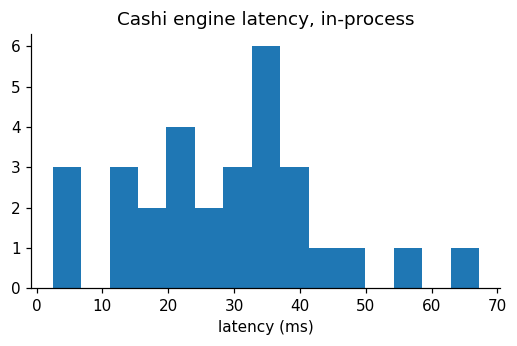

In [6]:
# Latency over repeated queries
import statistics
lat = []
for q in qs*6:
    lat.append(ask(q)[1])
print(f'n={len(lat)}  median {statistics.median(lat):.0f} ms  p95 {np.percentile(lat,95):.0f} ms  max {max(lat):.0f} ms')
plt.figure(figsize=(5.5,3)); plt.hist(lat, bins=15); plt.xlabel('latency (ms)'); plt.title('Cashi engine latency, in-process'); plt.show()

In [7]:
# Verification also exposes a real weakness: 'division centro' / 'division sur' are NOT resolved as filters
for q in ['gasto de nomina en direccion norte semana 38', 'gasto de nomina en division centro semana 38']:
    rr, _ = ask(q)
    print(q)
    print('  filters interpreted:', rr.get('filtros_interpretados'))
    print('  real_2026 (MDP):', rr.get('real_2026_mdp'))
print()
print('The second question silently falls back to the account-group total because the division name was not recognised.')
print('Payroll exists only in Direccion Norte in this demo, so the totals coincide, but the answer to that question is wrong.')
print('The interpreted-filters field makes the problem detectable.')

gasto de nomina en direccion norte semana 38
  filters interpreted: {'entidad': "División 'Direccion Norte' + Grupo 'Gastos de Nomina'", 'semanas': '38–38'}
  real_2026 (MDP): 0.6849695699999999
gasto de nomina en division centro semana 38
  filters interpreted: {'entidad': "Grupo 'Gastos de Nomina'", 'semanas': '38–38'}
  real_2026 (MDP): 0.6849695699999999

The second question silently falls back to the account-group total because the division name was not recognised.
Payroll exists only in Direccion Norte in this demo, so the totals coincide, but the answer to that question is wrong.
The interpreted-filters field makes the problem detectable.


## Results
See the outputs above: five natural-language questions answered with tables and SQL lineage, the numeric cross-check against pandas, the latency distribution and one failure case (an unresolved division filter).

## Conclusions
1. **Numbers are computed, not generated, and they check out.** The engine's payroll answer for Direccion Norte, week 38 (real 0.68, plan 0.67, last year 0.61 MDP) matches an independent pandas computation on the raw data, and the global variance answer (real 105,063,453.6 vs plan 102,003,353.0, +3.0%) matches exactly. Every answer ships its SQL lineage, so a user can audit it.
2. **It is fast enough for interactive use.** In-process latency over 30 queries is a median of 30 ms and a p95 of 53 ms (maximum 67 ms), because answers come from pre-aggregated tables rather than from a model call. This excludes the HTTP layer and any LLM-based phrasing.
3. **A real bug found by the verification.** "Division centro" and "division sur" are not recognised as filters (only the exact name "Direccion Norte" is), so the question silently falls back to the account-group total. The answer is wrong for that question and only the `filtros_interpretados` field reveals it. In production the engine should refuse or ask for clarification when a recognised dimension word (division, territory) is not resolved, and the response should say which filters were applied.
4. **Limits.** The data is synthetic (774 rows, 3 divisions, 5 account groups); the conceptual question "como se calcula el sobregasto" is answered with a generic variance table instead of an explanation, which shows the intent router needs a documentation route for definitional questions; and the knowledge base is not included in this public demo.

**Takeaway for the interview:** the design principle is that an LLM-style assistant over financial data should compute numbers deterministically, show its lineage, and expose the filters it interpreted. The verification step (recompute independently) is what found the filter bug.